# Introduction to the data class

`ProteinDataset` is an ordinary `torch.utils.data.Dataset` over one of the CSVs in `data/`. It
tokenises every sequence once, when it is constructed, and serves both of the project's targets
from the same `x`:

| Item | Shape | What it is |
|---|---|---|
| `x` | `(129,)` long | `<BOS>`, the residues, `<EOS>`, then `<PAD>` |
| `x_shifted` | `(129,)` long | `x` shifted left by one: the next-token target, `-1` past the end |
| `y` | scalar long | the family, as a class index |
| `length` | int | the number of residues, without the special tokens |


In [1]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

## The vocabulary

The token ids are fixed in `protgen.data`, not inferred from the data, so an id means the same
residue in every run and checkpoint: `<PAD>` 0, `<BOS>` 1, `<EOS>` 2, then the 20 standard
residues in alphabetical order. `encode` and `decode` go between a residue string and a token
tensor, and `decode` drops the special tokens - so decoding either `x` or `x_shifted` gives the
protein back.

In [2]:
from protgen.data import AA, FAMILIES, IGNORE_INDEX, special_tokens

print(f"vocab ({train_data.vocab_size} tokens): {train_data.vocab}")
print(f"families: {train_data.fam_to_idx}")
print(f"padding is ignored in the loss with ignore_index={IGNORE_INDEX}")

sequence = train_data.df["sequence"][0]
tokens = train_data.encode(sequence)
print()
print(f"encode / decode round-trips: {train_data.decode(tokens) == sequence}")
print(f"and from the shifted target too:  {train_data.decode(x_shifted) == sequence}")

vocab (23 tokens): {'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'A': 3, 'C': 4, 'D': 5, 'E': 6, 'F': 7, 'G': 8, 'H': 9, 'I': 10, 'K': 11, 'L': 12, 'M': 13, 'N': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'V': 20, 'W': 21, 'Y': 22}
families: {'AcyP': 0, 'HPr': 1, 'HU': 2}
padding is ignored in the loss with ignore_index=-1

encode / decode round-trips: True
and from the shifted target too:  True


## The two tasks

Both losses read the same `x`. The generative one predicts every residue from the ones before it,
with `ignore_index` making the padding free of loss; the classification one predicts the family of
the whole sequence. Stand-ins for the logits below, since the model is yours to write.

In [3]:
import torch
import torch.nn.functional as F

x, x_shifted, y, length = next(iter(train_loader))
print(f"batch: x {tuple(x.shape)} {x.dtype}, x_shifted {tuple(x_shifted.shape)}, y {tuple(y.shape)}")

# Generative: one distribution over the vocabulary per position.
logits_gen = torch.randn(x.shape[0], train_data.vocab_size, train_data.max_length)
print(f"generative loss:     {F.cross_entropy(logits_gen, x_shifted, ignore_index=IGNORE_INDEX):.4f}")

# Classification: one distribution over the three families per sequence.
logits_fam = torch.randn(x.shape[0], len(FAMILIES))
print(f"classification loss: {F.cross_entropy(logits_fam, y):.4f}")

batch: x (32, 129) torch.int64, x_shifted (32, 129), y (32,)
generative loss:     3.6195
classification loss: 1.3638


## Next

Write your model in `src/protgen/models/`, and have your sampling code write a CSV with a
`sequence` column to `results/sequences/<name>.csv`. That is the only thing the evaluation asks
for:

```bash
uv run python eval/eval.py --samples results/sequences/mock_data.csv
```

`results/sequences/mock_data.csv` ships with the repo, so that command runs today. See
[`eval/README.md`](../eval/README.md) for what the numbers mean, and make the controls
(`eval/make_controls.py`) before reading any of them.

In [78]:
import torch
from torch import nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
hidden_layer_nodes = 10
#num_features = 3 # The three vakues in the sting of protein
num_features = train_data.vocab_size # The three vakues in the sting of protein, but this have I made as a array that is onehot encoded
num_output = train_data.vocab_size # The number of of possible values

class Net(nn.Module):

    def __init__(self):
        super(Net, self).__init__()
        # Setting up variables, these variables are weights in your 
        # network that can be updated while running our graph.
        # Notice, to make a hidden layer, the weights need to have the 
        # following dimensionality:
        #   W[number_of_units_going_out, number_of_units_going_in]
        #   b[number_of_units_going_out]
        # in the example below we have 2 input units (num_features) and 2 output units (num_output)
        # so our weights become W[2, 2], b[2]
        # if we want to make a hidden layer with 100 units, we need to define the shape of the
        # first weight to W[100, 2], b[2] and the shape of the second weight to W[2, 100], b[2]
        
        # first layer
        #self.W_1 = nn.Parameter(torch.randn(num_output, num_features)) 
        #self.b_1 = nn.Parameter(torch.randn(num_output))
        self.embed = nn.Embedding(num_features, 128)
        self.W_1 = nn.Parameter(torch.randn(hidden_layer_nodes, 128)) 
        self.b_1 = nn.Parameter(torch.randn(hidden_layer_nodes))
                
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        self.W_2 = nn.Parameter(torch.randn(hidden_layer_nodes, hidden_layer_nodes))
        self.b_2 = nn.Parameter(torch.randn(hidden_layer_nodes))

        self.W_3 = nn.Parameter(torch.randn(num_output, hidden_layer_nodes))
        self.b_3 = nn.Parameter(torch.randn(num_output))
        
    def forward(self, x):
        # Setting up ops, these ops will define edges along our computational graph
        # The below ops will compute a logistic regression, 
        # but can be modified to compute a neural network
        x = self.embed(x) 
        x = F.linear(x, self.W_1, self.b_1) # være rigtige dimensioner 
        
        # second layer (to be completed as an exercise)
        # NB when you create a second layer, remember that you also must change parts of the first layer
        #x = F.linear(x, self.W_2, self.b_2)
        x = F.relu(x)
        x = F.linear(x, self.W_2, self.b_2)

        x = F.relu(x)
        x = F.linear(x, self.W_3, self.b_3)

        return F.softmax(x, dim=1) # softmax to be performed on the second dimension

net = Net()

In [106]:
def cross_entropy(ys, ts):
    # computing cross entropy per sample
    cross_entropy = -torch.sum(ts * torch.log(ys), dim=1, keepdim=False)
    # averaging over samples
    return torch.mean(cross_entropy)

In [107]:
import torch.optim as optim

optimizer = optim.SGD(net.parameters(), lr=0.01)

In [108]:
def accuracy(ys, ts):
    # making a one-hot encoded vector of correct (1) and incorrect (0) predictions
    correct_prediction = torch.eq(torch.max(ys, 1)[1], torch.max(ts, 1)[1])
    # averaging the one-hot encoded vector
    return torch.mean(correct_prediction.float())

In [109]:
def onehot(t, num_classes):
    out = np.zeros((t.shape[0], num_classes))
    for row, col in enumerate(t):
        out[row, col] = 1
    return out

In [110]:
batch_size_ = 32*4
train_loader = DataLoader(train_data, batch_size=batch_size_, shuffle=True)
val_loader = DataLoader(val_data, batch_size=batch_size_, shuffle=True)

In [111]:
size_of_traindata = len(train_data)

Epoch 0, Train Cost: 11.427	Val Cost: 9.691	 Val acc: 0.000
Epoch 100, Train Cost: 0.070	Val Cost: 0.056	 Val acc: 0.992


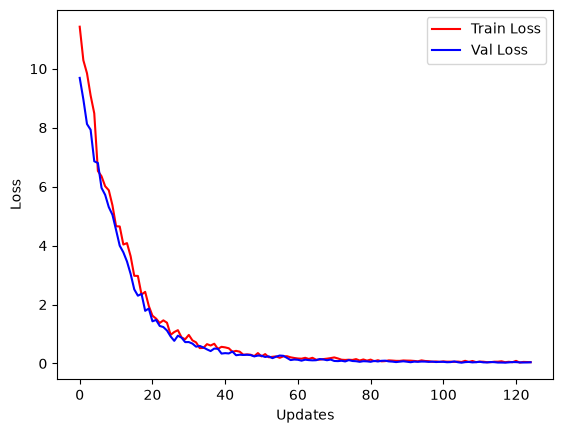

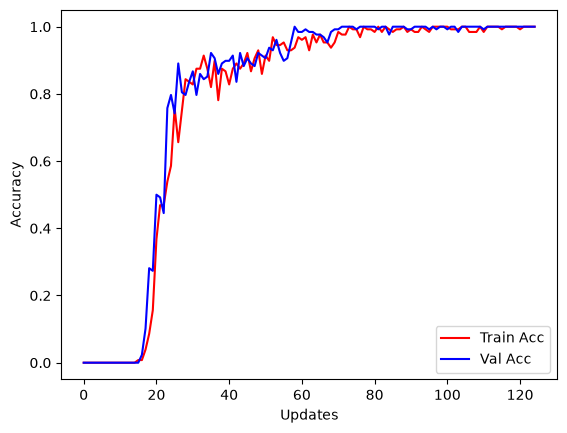

In [112]:
# number of training passses
num_epochs = int(np.floor(size_of_traindata/batch_size_))
# store loss and accuracy for information
train_losses, val_losses, train_accs, val_accs = [], [], [], []

def pred(X):
    """ Compute graph's prediction and return numpy array
    
    Parameters
    ----------
    X : numpy.ndarray
    
    Returns
    -------
    numpy.ndarray
    """
    X = torch.from_numpy(X)
    y = net(X)
    return y.data.numpy()

# training loop
for e in range(num_epochs):
    x, x_shifted, y, length = next(iter(train_loader))
    X_tr = x_shifted[:, 0:3]
    y_tr = x[:, 0]
    # get training input and expected output as torch Variables and make sure type is correct
    tr_input = torch.from_numpy(onehot(X_tr, num_output)).float() #X_tr#torch.from_numpy(onehot(X_tr, num_output)).float()# torch.from_numpy(X_tr)
    tr_targets = torch.from_numpy(onehot(y_tr, num_output)).float() #y_tr#torch.from_numpy(onehot(y_tr, num_output)).float()
    
    # zeroize accumulated gradients in parameters
    optimizer.zero_grad()
    # predict by running forward pass
    tr_output = net(tr_input)
    # compute cross entropy loss
    tr_loss = cross_entropy(tr_output, tr_targets)
    # compute gradients given loss
    tr_loss.backward()
    # update the parameters given the computed gradients
    optimizer.step()
    train_acc = accuracy(tr_output, tr_targets)
    
    # store training loss
    train_losses.append(tr_loss.data.numpy())
    train_accs.append(train_acc)

    x_, x_shifted_, y_, length_ = next(iter(val_loader))
    X_val = x_shifted_[:, 0:3]
    y_val = x_[:, 0]
    # get validation input and expected output as torch Variables and make sure type is correct
    val_input = torch.from_numpy(onehot(X_val, num_output)).float()  #torch.from_numpy(X_val)
    val_targets = torch.from_numpy(onehot(y_val, num_output)).float()  #torch.from_numpy(onehot(y_val, num_output)).float()
    
    # predict with validation input
    val_output = net(val_input)
    # compute loss and accuracy
    val_loss = cross_entropy(val_output, val_targets)
    val_acc = accuracy(val_output, val_targets)
    
    # store loss and accuracy
    val_losses.append(val_loss.data.numpy())
    val_accs.append(val_acc.data.numpy())
    
    if e % 100 == 0:
        print("Epoch %i, "
              "Train Cost: %0.3f"
              "\tVal Cost: %0.3f"
              "\t Val acc: %0.3f" % (e, 
                                     train_losses[-1],
                                     val_losses[-1],
                                     val_accs[-1]))
        
        
## get test input and expected output
#te_input = torch.from_numpy(X_te)
#te_targets = torch.from_numpy(onehot(y_te, num_output)).float()
## predict on testset
#te_output = net(te_input)
## compute loss and accuracy
#te_loss = cross_entropy(te_output, te_targets)
#te_acc = accuracy(te_output, te_targets)
#print("\nTest Cost: %0.3f\tTest Accuracy: %0.3f" % (te_loss.data.numpy(), te_acc.data.numpy()))

plt.figure()
epoch = np.arange(len(train_losses))
plt.plot(epoch, train_losses, 'r', label='Train Loss')
plt.plot(epoch, val_losses, 'b', label='Val Loss')
plt.legend()
plt.xlabel('Updates')
plt.ylabel('Loss')
plt.show()

plt.figure()
plt.plot(epoch, train_accs, 'r', label='Train Acc')
plt.plot(epoch, val_accs, 'b', label='Val Acc')
plt.legend()
plt.xlabel('Updates')
plt.ylabel('Accuracy')
plt.show()

In [68]:
tr_targets

tensor([[0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0.],
 

In [65]:
tr_targets.dtype = float

AttributeError: attribute 'dtype' of 'torch._C.TensorBase' objects is not writable

In [62]:
X_tr

tensor([[13, 17,  8],
        [13, 14, 11],
        [13, 22, 16],
        [13, 19,  6],
        [13,  3,  6],
        [13, 15, 18],
        [13,  3, 16],
        [13, 14, 17],
        [13, 10, 17],
        [13,  8, 10],
        [13,  6, 17],
        [13, 19, 20],
        [13, 18,  5],
        [13,  3,  9],
        [13, 15, 20],
        [13, 18, 14],
        [13,  6, 11],
        [13, 15,  3],
        [13, 10, 15],
        [13, 15, 11],
        [13, 13,  5],
        [13, 18,  5],
        [13, 14, 11],
        [13, 14, 17],
        [13, 19, 11],
        [13, 10, 17],
        [13, 18, 19],
        [13,  3, 11],
        [13, 19, 11],
        [13, 16, 15],
        [13, 18,  3],
        [13, 18, 14]])